# 09 · Geometric transforms and document rectification

**Level:** Intermediate  
**Prerequisites:** Notebooks 01–08; coordinates, arrays, and interpolation.

## What you will build and learn

- Apply translation, rotation, and perspective transforms.
- Keep source-to-destination coordinates consistent.
- Transform points and images with the same matrix.
- Rectify a synthetic photographed document and measure alignment.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Build a reference document
We know the original geometry, so we can check a warp quantitatively. A transformation maps coordinates; interpolation determines sampled pixel values. OpenCV output sizes are `(width, height)`, whereas array shapes begin `(height, width)`.


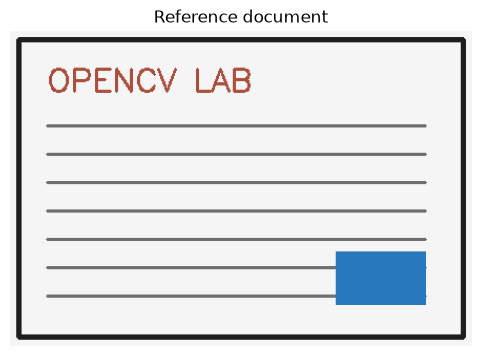

In [2]:
doc = np.full((300, 440, 3), 245, np.uint8)
cv2.rectangle(doc, (8, 8), (431, 291), (30, 30, 30), 3)
cv2.putText(doc, 'OPENCV LAB', (35, 57), cv2.FONT_HERSHEY_SIMPLEX, 1, (60, 80, 170), 2)
for y in range(90, 255, 27):
    cv2.line(doc, (35, y), (395, y), (110, 110, 110), 2)
cv2.rectangle(doc, (310, 210), (395, 260), (190, 120, 40), -1)
h, w = doc.shape[:2]
show_images([doc], ['Reference document'])


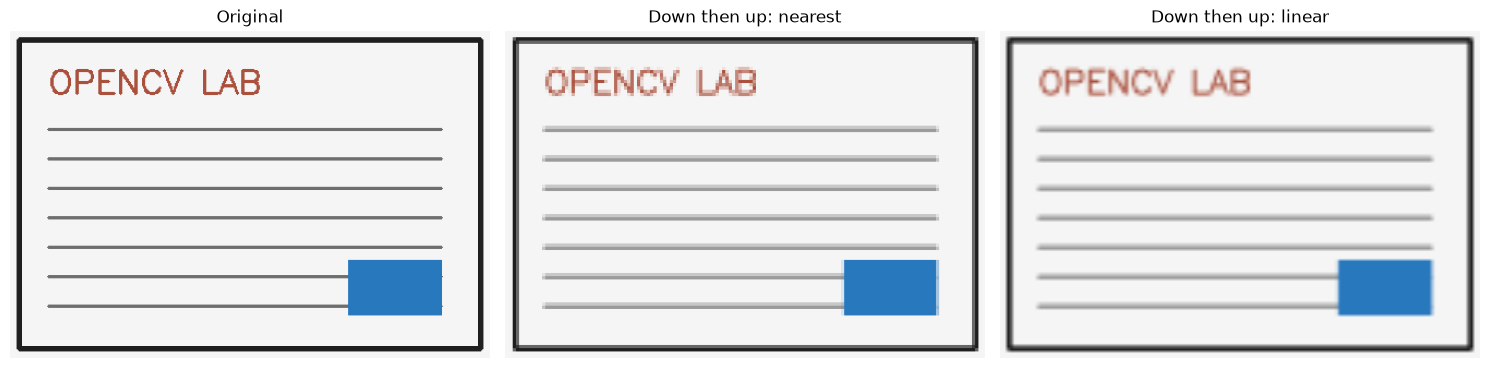

Resizing discards information; enlargement cannot recover it.


In [3]:
small = cv2.resize(doc, (w // 3, h // 3), interpolation=cv2.INTER_AREA)
nearest = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
linear = cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
show_images([doc, nearest, linear], ['Original', 'Down then up: nearest', 'Down then up: linear'])
print('Resizing discards information; enlargement cannot recover it.')


## Step 2 — Translate and rotate using 2×3 affine matrices
An affine transform preserves straight lines and parallelism. Translation uses `[[1,0,tx],[0,1,ty]]`. Positive x moves right; positive y moves down. `warpAffine` internally samples the source for each destination pixel; pass the forward source-to-destination matrix unless using `WARP_INVERSE_MAP`.


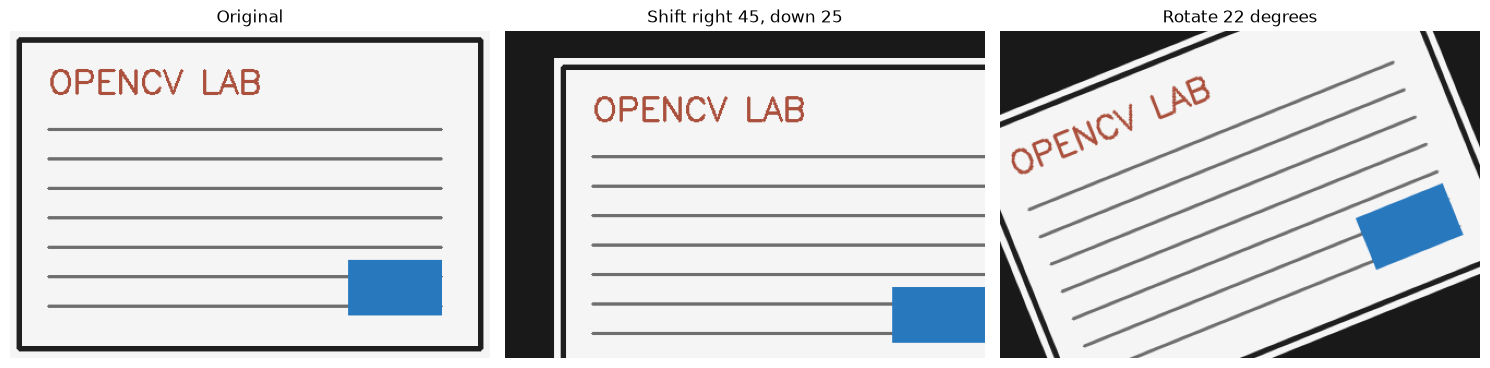

In [4]:
translation = np.float32([[1, 0, 45], [0, 1, 25]])
shifted = cv2.warpAffine(doc, translation, (w, h), borderValue=(25, 25, 25))
rotation = cv2.getRotationMatrix2D(((w - 1) / 2, (h - 1) / 2), 22, 1.0)
rotated = cv2.warpAffine(doc, rotation, (w, h), borderValue=(25, 25, 25))
show_images([doc, shifted, rotated], ['Original', 'Shift right 45, down 25', 'Rotate 22 degrees'])


In [5]:
point = np.float32([[[35, 57]]])
shifted_point = cv2.transform(point, translation)[0, 0]
rotated_point = cv2.transform(point, rotation)[0, 0]
print('Original point:', point[0, 0])
print('Translated point:', shifted_point)
print('Rotated point:', rotated_point)
assert np.allclose(shifted_point, [80, 82])


Original point: [35. 57.]
Translated point: [80. 82.]
Rotated point: [ 13.783466 132.8504  ]


A fixed output canvas crops rotated corners. Enlarge the canvas and adjust the translation terms to keep the rotated image centered. Use image dimensions for the canvas bounds; minor one-pixel border differences come from pixel-center conventions.


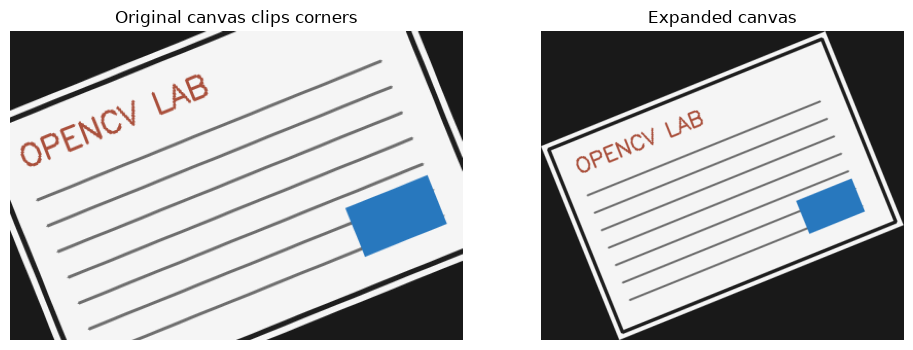

In [6]:
cosine, sine = abs(rotation[0, 0]), abs(rotation[0, 1])
bound_w = int(np.ceil(w * cosine + h * sine))
bound_h = int(np.ceil(h * cosine + w * sine))
expanded_rotation = rotation.copy()
expanded_rotation[0, 2] += (bound_w - w) / 2
expanded_rotation[1, 2] += (bound_h - h) / 2
uncropped = cv2.warpAffine(doc, expanded_rotation, (bound_w, bound_h), borderValue=(25, 25, 25))
show_images([rotated, uncropped], ['Original canvas clips corners', 'Expanded canvas'], cols=2)
assert uncropped.shape[:2] == (bound_h, bound_w)


## Step 3 — Compose transforms before resampling
Use 3×3 homogeneous matrices to compose affine transforms. For column-vector coordinates, `B @ A` applies A first and B second. A single warp usually retains more detail than repeatedly resampling the image.


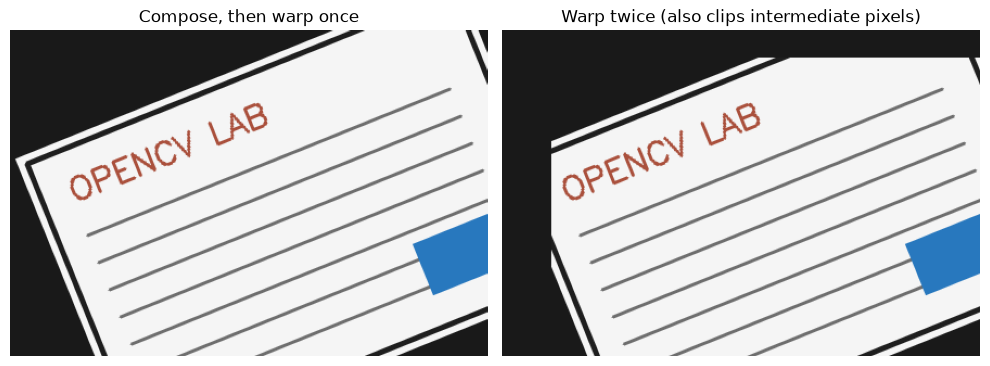

In [7]:
T = np.vstack([translation, [0, 0, 1]])
R = np.vstack([rotation, [0, 0, 1]])
combined = T @ R  # rotation, then translation
one_pass = cv2.warpAffine(doc, combined[:2], (w, h), borderValue=(25, 25, 25))
two_pass = cv2.warpAffine(rotated, translation, (w, h), borderValue=(25, 25, 25))
show_images([one_pass, two_pass], ['Compose, then warp once', 'Warp twice (also clips intermediate pixels)'], cols=2)
p_h = np.array([35, 57, 1.0])
assert np.allclose(combined @ p_h, T @ (R @ p_h))


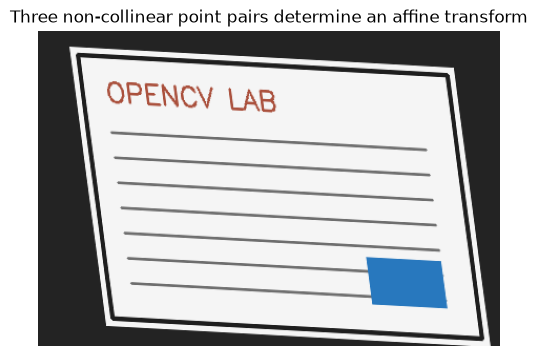

In [8]:
source_triangle = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])
target_triangle = np.float32([[30, 15], [w - 45, 35], [65, h - 20]])
affine = cv2.getAffineTransform(source_triangle, target_triangle)
sheared = cv2.warpAffine(doc, affine, (w, h), borderValue=(35, 35, 35))
show_images([sheared], ['Three non-collinear point pairs determine an affine transform'])
assert np.allclose(cv2.transform(source_triangle[None], affine)[0], target_triangle, atol=1e-3)


## Step 4 — Perspective warp using four ordered corners
A homography models a planar surface under perspective. It has eight independent degrees of freedom after scale normalization. Four point pairs must be in matching order and must not be degenerate. We use top-left, top-right, bottom-right, bottom-left for both arrays.


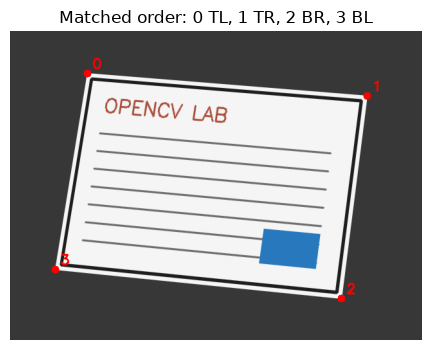

In [9]:
source_corners = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
photo_corners = np.float32([[120, 65], [555, 100], [515, 415], [70, 370]])
H_forward = cv2.getPerspectiveTransform(source_corners, photo_corners)
photo = cv2.warpPerspective(doc, H_forward, (640, 480), borderValue=(55, 55, 55))
corner_view = photo.copy()
for i, p in enumerate(photo_corners.astype(int)):
    cv2.circle(corner_view, tuple(p), 6, (0, 0, 255), -1)
    cv2.putText(corner_view, str(i), tuple(p + [8, -8]), cv2.FONT_HERSHEY_SIMPLEX, .7, (0, 0, 255), 2)
show_images([corner_view], ['Matched order: 0 TL, 1 TR, 2 BR, 3 BL'])


In [10]:
mapped_corners = cv2.perspectiveTransform(source_corners[None], H_forward)[0]
corner_error = np.linalg.norm(mapped_corners - photo_corners, axis=1)
print('Forward corner errors (pixels):', corner_error)
assert corner_error.max() < .001
print('H matrix:'); print(H_forward)


Forward corner errors (pixels): [0. 0. 0. 0.]
H matrix:
[[ 9.55269805e-01 -1.73077954e-01  1.20000000e+02]
 [ 7.33088897e-02  9.89124987e-01  6.50000000e+01]
 [-6.41776180e-05 -8.36267632e-05  1.00000000e+00]]


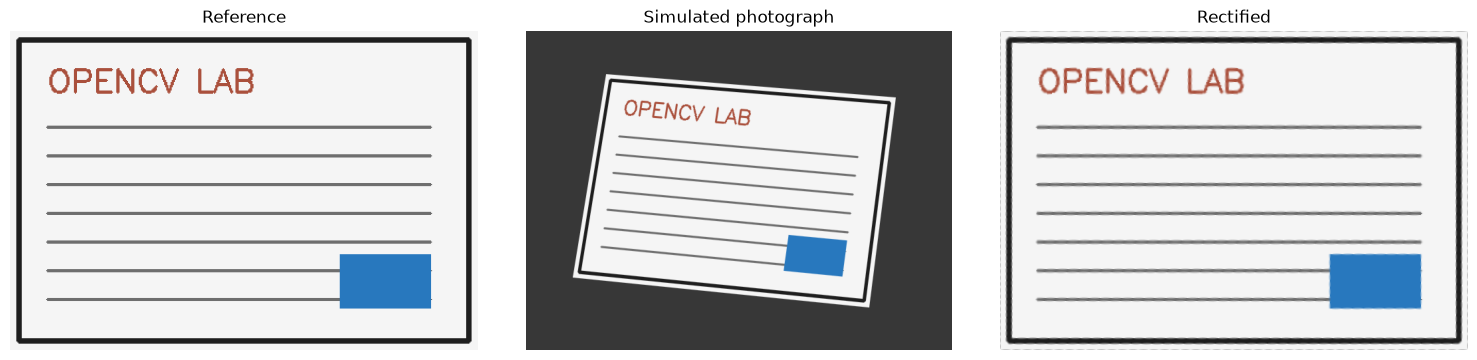

In [11]:
H_inverse = cv2.getPerspectiveTransform(photo_corners, source_corners)
rectified = cv2.warpPerspective(photo, H_inverse, (w, h))
show_images([doc, photo, rectified], ['Reference', 'Simulated photograph', 'Rectified'])
inverse_check = H_inverse @ H_forward
inverse_check /= inverse_check[2, 2]
assert np.allclose(inverse_check, np.eye(3), atol=1e-5)


## Step 5 — Mini-project: quantify rectification quality
Correct point geometry does not imply identical pixels: two interpolation passes blur edges. Compare an interior region to avoid border artifacts. Then perturb the measured corners and observe how geometric annotation errors affect the result.


Interior mean absolute pixel error: 2.398 / 255


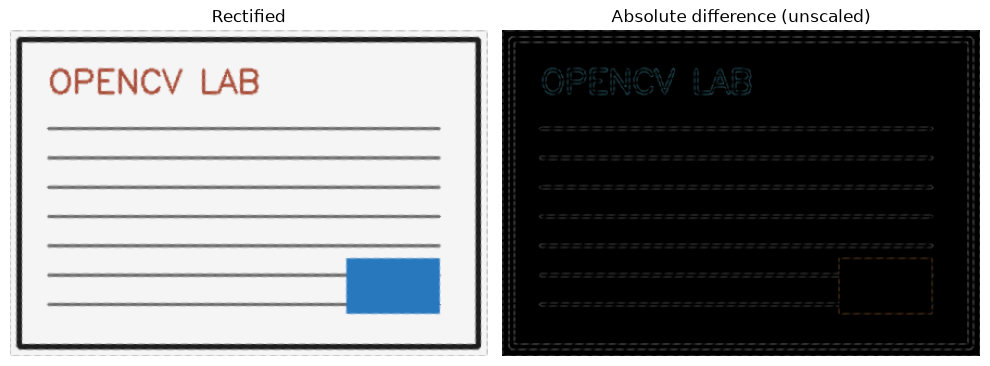

In [12]:
interior = np.s_[15:-15, 15:-15]
mae = np.mean(np.abs(rectified[interior].astype(np.float32) - doc[interior].astype(np.float32)))
difference = cv2.absdiff(doc, rectified)
print(f'Interior mean absolute pixel error: {mae:.3f} / 255')
show_images([rectified, difference], ['Rectified', 'Absolute difference (unscaled)'], cols=2)


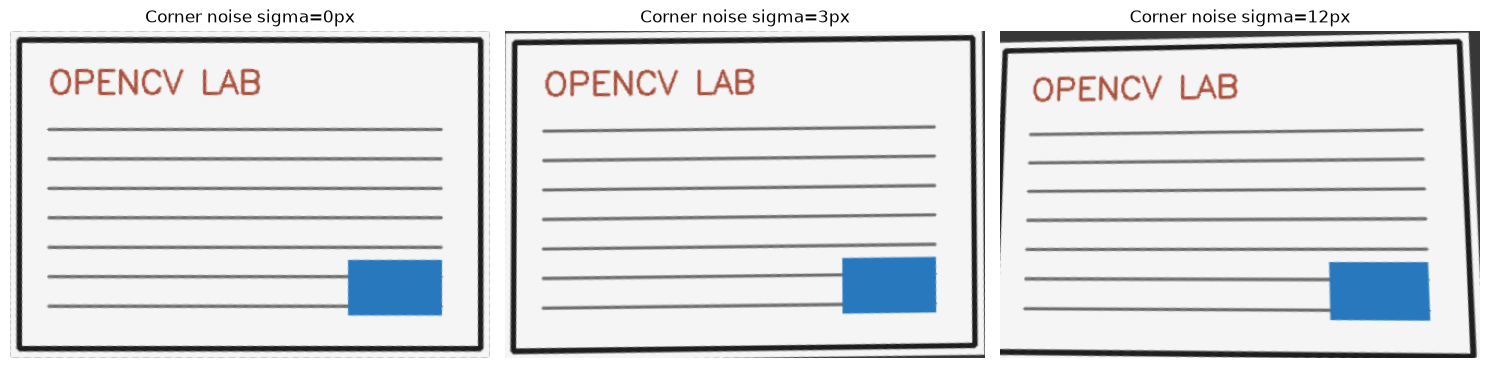

Interior MAE: [ 2.4   7.64 17.82]


In [13]:
errors = []
views = []
for sigma in [0, 3, 12]:
    measured = photo_corners + rng.normal(0, sigma, photo_corners.shape).astype(np.float32)
    estimate = cv2.getPerspectiveTransform(measured, source_corners)
    recovered = cv2.warpPerspective(photo, estimate, (w, h))
    errors.append(np.mean(np.abs(recovered[interior].astype(float) - doc[interior].astype(float))))
    views.append(recovered)
show_images(views, [f'Corner noise sigma={s}px' for s in [0, 3, 12]])
print('Interior MAE:', np.round(errors, 2))


In [14]:
out_dir = ROOT / 'outputs' / '09_geometry'
out_dir.mkdir(parents=True, exist_ok=True)
save_image(out_dir / 'perspective_photo.png', photo)
save_image(out_dir / 'rectified_document.png', rectified)
np.save(out_dir / 'photo_to_document_homography.npy', H_inverse)
print('Saved images and a reusable transformation matrix to', out_dir)


Saved images and a reusable transformation matrix to C:\Users\Hareram ray\AI\OpencvPractical\outputs\09_geometry


### Pitfalls and practice
- Use nearest-neighbor interpolation for class-label masks. Linear interpolation invents intermediate labels.
- Four arbitrary points do not guarantee a useful homography; they must span a plane and correspond correctly.
- A homography cannot model general depth changes, curved paper, or lens distortion.

1. Translate the document left 30 pixels and down 40 pixels; verify one point numerically.
2. Warp a binary mask using both nearest and linear interpolation. Inspect unique values.
3. Verify the inverse by mapping the four photographed corners back to the document.


## Worked solutions
Keep the same output coordinate convention for points and pixels.


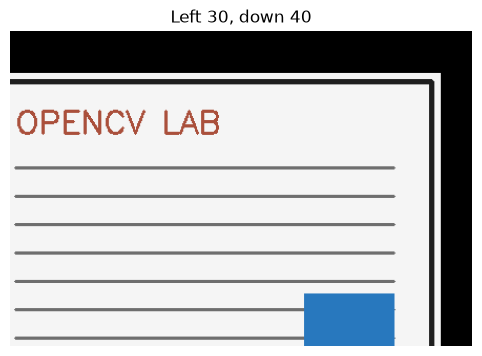

In [15]:
exercise_translation = np.float32([[1, 0, -30], [0, 1, 40]])
exercise_image = cv2.warpAffine(doc, exercise_translation, (w, h))
exercise_point = cv2.transform(np.float32([[[100, 100]]]), exercise_translation)[0, 0]
assert np.allclose(exercise_point, [70, 140])
show_images([exercise_image], ['Left 30, down 40'])


Nearest values: [  0 255]
Linear has 35 distinct values


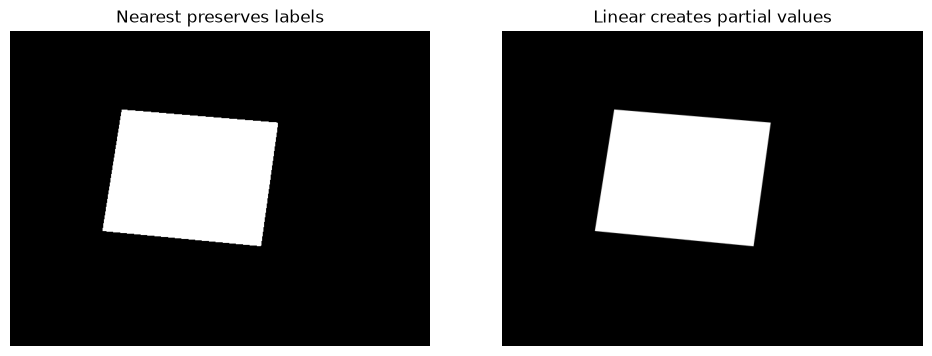

In [16]:
binary = np.zeros((h, w), np.uint8)
cv2.rectangle(binary, (60, 50), (300, 230), 255, -1)
mask_nearest = cv2.warpPerspective(binary, H_forward, (640, 480), flags=cv2.INTER_NEAREST)
mask_linear = cv2.warpPerspective(binary, H_forward, (640, 480), flags=cv2.INTER_LINEAR)
print('Nearest values:', np.unique(mask_nearest))
print('Linear has', len(np.unique(mask_linear)), 'distinct values')
assert set(np.unique(mask_nearest)).issubset({0, 255})
recovered_corners = cv2.perspectiveTransform(photo_corners[None], H_inverse)[0]
assert np.allclose(recovered_corners, source_corners, atol=.001)
show_images([mask_nearest, mask_linear], ['Nearest preserves labels', 'Linear creates partial values'], cols=2)


### Reflection
Explain why the inverse matrix can be numerically correct while the reconstructed pixels differ. How would you collect corner correspondences for a real document? Notebook 10 estimates correspondences from visual features.

Official references: [Geometric transformations](https://docs.opencv.org/4.x/da/d6e/tutorial_py_geometric_transformations.html), [Transform API and interpolation](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html).
